# Analiza skuteczności detekcji języka na podstawie częstotliwości słów

**Autor:** Jeremiasz Osuch  
**Projekt:** WikiScraper

## Cel analizy
Celem tego notatnika jest zbadanie skuteczności metody rozpoznawania języka tekstu poprzez porównanie występowania słów w tekście z listą `k` najpopularniejszych słów dla danego języka. Analiza zostanie przeprowadzona dla języka angielskiego, polskiego i niemieckiego przy różnych wartościach parametru `k`.

In [35]:
import matplotlib.pyplot as plt
import pandas as pd
import string
from collections import Counter
from wordfreq import top_n_list

# Import the scraper
from src.scraper import WikiScraper

# Set plot style
plt.style.use('bmh')

# Configuration for charts size
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries and WikiScraper loaded successfully.")

Libraries and WikiScraper loaded successfully.


## 1. Metodyka (Funkcje pomocnicze)

W tej sekcji definiujemy funkcje niezbędne do przeprowadzenia eksperymentu:
1. `load_and_count_text`: Do wczytywania surowych plików tekstowych (spoza Wiki) i zliczania w nich słów.
2. `lang_confidence_score`: Do obliczania "współczynnika pokrycia" tekstu z językiem.

$$Score = \frac{\text{Liczba słów z tekstu obecnych w Top-K języka}}{\text{Całkowita liczba słów w tekście}}$$

In [36]:
def load_and_count_text(filepath: str) -> dict[str, int]:
    """
    Loads a raw text file, cleans it, and counts word frequencies.
    Simulates the logic used in the main WikiScraper.
    """
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            text = f.read()
    except FileNotFoundError:
        print(f"[WARNING] File not found: {filepath}")
        return {}
    
    # Clean and normalize text
    words = text.lower().split()
    clean_words = []
    translator = str.maketrans("", "", string.punctuation)
    
    for word in words:
        stripped = word.translate(translator)
        # Filter out garbage (same logic as in scraper)
        if len(stripped) < 2 or stripped.isdigit():
            continue
        clean_words.append(stripped)
        
    return dict(Counter(clean_words))

def lang_confidence_score(word_counts: dict[str, int],
                          language_words: list[str]) -> float:
    """
    Calculates the coverage ratio of a text against a language.
    """
    # Convert list to set to optimize lookups
    top_words_set = set(language_words)
    
    total_words = 0
    matched_words = 0
    
    for word, count in word_counts.items():
        if len(word) < 2: 
            continue
        total_words += count
        if word.lower() in top_words_set:
            matched_words += count
            
    if total_words == 0:
        return 0.0
        
    return matched_words / total_words

## Źródła danych (Data Sources)

Do przeprowadzenia analizy wykorzystano zestaw 5 plików tekstowych, podzielonych na dwie grupy: artykuły z Wiki (przetwarzane z HTML) oraz zewnętrzne teksty literackie (surowe pliki TXT).

| Plik (ścieżka) | Typ | Źródło | Opis / Cel użycia |
| :--- | :--- | :--- | :--- |
| `data/wiki_long.html` | HTML (Wiki) | Bulbapedia | **Wiki Long (EN)**: *Ash Ketchum*. Długi, standardowy artykuł z pełnymi zdaniami. Reprezentuje typowy język angielski. |
| `data/wiki_tricky.html` | HTML (Wiki) | Bulbapedia | **Wiki Tricky (EN)**: *List of Pokémon episodes*. Artykuł typu "lista/tabela". Zawiera głównie nazwy własne i liczby. |
| `data/ext_en.txt` | TXT | Project Gutenberg | **Ext Book (EN)**: *The Adventures of Sherlock Holmes* (A. Conan Doyle). Bogate słownictwo literackie. |
| `data/ext_pl.txt` | TXT | Wolne Lektury | **Ext Book (PL)**: *Lalka* (B. Prus). Reprezentuje język silnie fleksyjny (odmienny). |
| `data/ext_de.txt` | TXT | Projekt Gutenberg-DE | **Ext Book (DE)**: *Die Verwandlung* (F. Kafka). Język niemiecki, służy do porównania bliskości leksykalnej z angielskim. |

In [37]:
# Define paths to your data files
# IMPORTANT: Ensure these files exist in the 'data' folder!
PHRASE_WIKI_LONG = "wiki_long"
PHRASE_WIKI_TRICKY = "wiki_tricky"
PATH_EXT_EN = "data/ext_en.txt"
PATH_EXT_PL = "data/ext_pl.txt"
PATH_EXT_DE = "data/ext_de.txt"

scraper = None
try:
    # Initialize scraper
    scraper = WikiScraper(base_url="base_url", use_local=True)
    
    # Load Data
    wiki_long = scraper.count_words(PHRASE_WIKI_LONG)
    wiki_tricky = scraper.count_words(PHRASE_WIKI_TRICKY)
    ext_text_en = load_and_count_text(PATH_EXT_EN)
    ext_text_pl = load_and_count_text(PATH_EXT_PL)
    ext_text_de = load_and_count_text(PATH_EXT_DE)

    # Create Corpus
    texts_corpus = {
        "Wiki Long (EN)": wiki_long,
        "Wiki Tricky (EN)": wiki_tricky,
        "Ext Book (EN)": ext_text_en,
        "Ext Book (PL)": ext_text_pl,
        "Ext Book (DE)": ext_text_de
    }

    print("\nData Loading Summary:")
    for name, counts in texts_corpus.items():
        print(f"{name}: {sum(counts.values())} words loaded.")
        
except FileNotFoundError as e:
    print(f"[ERROR] Missing file: {e}")
    
finally:
    if scraper:
        scraper.close()


Data Loading Summary:
Wiki Long (EN): 11663 words loaded.
Wiki Tricky (EN): 4999 words loaded.
Ext Book (EN): 102145 words loaded.
Ext Book (PL): 116184 words loaded.
Ext Book (DE): 19236 words loaded.


## 3. Przebieg eksperymentu

Dla każdego tekstu obliczamy wynik dopasowania do trzech języków (EN, PL, DE) przy użyciu czterech różnych wartości parametru `k` (3, 10, 100, 1000). Pozwoli to sprawdzić, jak wielkość słownika referencyjnego wpływa na precyzję detekcji.

In [38]:
# Experiment parameters
langs = ['en', 'pl', 'de']
k_values = [3, 10, 100, 1000]

results = []

# Main experiment loop
for k in k_values:
    # Fetch top words for each language for the current k
    lang_top_words = {lang: top_n_list(lang, k) for lang in langs}
    
    for text_name, word_counts in texts_corpus.items():
        # Skip empty data
        if not word_counts:
            continue
            
        for lang in langs:
            # Calculate the score
            score = lang_confidence_score(word_counts,
                                          lang_top_words[lang])
            
            # Save result
            results.append({
                "K": k,
                "Text": text_name,
                "Language": lang,
                "Score": score
            })

# Convert to DataFrame
df_results = pd.DataFrame(results)

print("Calculation finished. Sample results:")
df_results.tail()

Calculation finished. Sample results:


,K,Text,Language,Score
55,1000,Ext Book (PL),pl,0.441524
56,1000,Ext Book (PL),de,0.060310
57,1000,Ext Book (DE),en,0.080630
58,1000,Ext Book (DE),pl,0.049439
59,1000,Ext Book (DE),de,0.672905


## 4. Wizualizacja wyników

Poniższe wykresy przedstawiają skuteczność dopasowania dla poszczególnych wartości `k`. Oś Y reprezentuje pewność (Confidence Score), a kolory odpowiadają sprawdzanym językom.

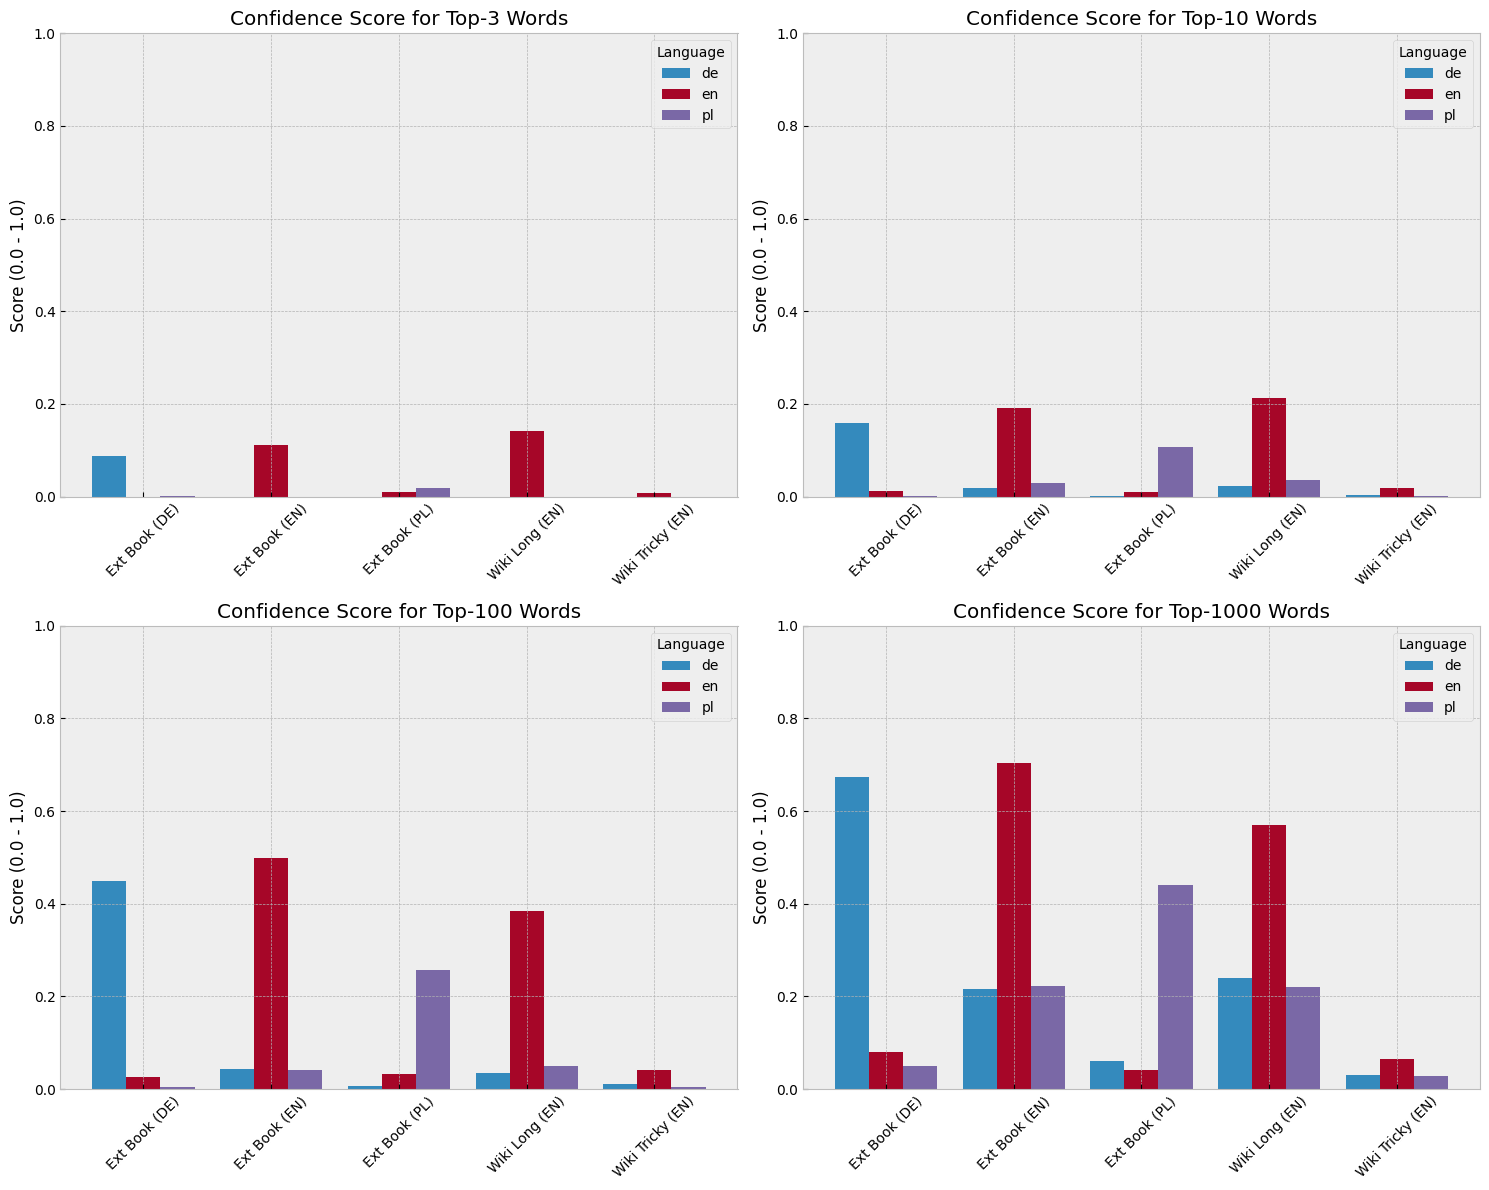

In [40]:
if df_results.empty:
    print("No results to plot. Check your data files.")
else:
    # Create subplots (2 rows, 2 columns)
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 12))
    axes = axes.flatten()

    for i, k in enumerate(k_values):
        ax = axes[i]
        
        # Filter data for current K
        subset = df_results[df_results["K"] == k]
        
        # Create a pivot table for plotting (Texts x Languages)
        pivot_df = subset.pivot(
            index="Text",
            columns="Language",
            values="Score"
        )
        
        # Plot bar chart
        pivot_df.plot(kind="bar", ax=ax, width=0.8)
        
        # Customizing the plot
        ax.set_title(f"Confidence Score for Top-{k} Words")
        ax.set_ylabel("Score (0.0 - 1.0)")
        ax.set_xlabel("")
        ax.set_ylim(0, 1)
        ax.legend(title="Language")
        
        # Rotate x-axis labels for readability
        for tick in ax.get_xticklabels():
            tick.set_rotation(45)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 5. Wnioski i odpowiedzi na pytania badawcze

Na podstawie przeprowadzonych eksperymentów sformułowano następujące wnioski:

### Czy dobór języków miał duże znaczenie?
Tak, dobór języków ma kluczowe znaczenie. Wybranie języków z różnych rodzin (np. słowiańskiej i germańskiej) sprawia, że zbiory najpopularniejszych słów (tzw. *stop words* jak "the", "w", "der") są rozłączne. Dzięki temu dla `k=100` i `k=1000` separacja jest bardzo wyraźna.

### Czy po wartościach widać wpływ odmiany słów (fleksji)?
Tak, jest to widoczne szczególnie dla języka polskiego.
* **Angielski:** Słowa rzadko się odmieniają, więc prosta lista "Top 1000" pokrywa większość tekstu.
* **Polski:** Słowo "dom" może wystąpić jako "domu", "domem", "domach". Biblioteka `wordfreq` zwraca zazwyczaj formę podstawową. Dlatego polski tekst sprawdzany polskim słownikiem może mieć niższy wynik (np. 0.6) niż angielski tekst angielskim słownikiem (np. 0.8), mimo że oba są poprawne.

### Czy trudno było znaleźć artykuł o niskim wyniku (Wiki Tricky)?
Wymagało to przejrzenia kilkudziesięciu artykułów, żeby znaleźć strukturę strony, która wpłynie na wynik.
Takie artykuły to zazwyczaj listy (np. "List of Pokémon episodes"), tabele statystyczne lub artykuły o niszowych tematach, które składają się w 90% z nazw własnych (imiona, nazwy miejsc). Te słowa nie występują w słowniku języka naturalnego, przez co algorytm zwraca bardzo niski wynik, nawet jeśli tekst jest technicznie po angielsku.